# Working with Textgrids

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import phonlab as phon
from IPython.display import Audio
import seaborn as sns

import importlib  # needed to get example audio/textgrids from package

print(phon.__name__,phon.__version__)

AUDIO = importlib.resources.files('phonlab') / 'data' / 'example_audio'

phonlab 0.0.69


## a. Recall this example audio file

* We'll compute a formants dataframe for it now at this step
* And we'll save it as a csv file.
* You can do this "compute and save" step once before tinkering with other analyses

In [5]:
example_audio = AUDIO / 'im_twelve.wav'
x, fs = phon.loadsig(example_audio)
fmtdf = phon.IFC_formants(x,fs,speaker=1)

fmtdf.to_csv("im_twelve.csv",index=False)  # here's a new thing - save a pandas dataframe as a csv file.

Audio(x,rate=fs)

### Exercise

Find the .csv file on your computer and open it

## b. There is also a TextGrid file for this wav file.

* Read two of the tiers from the TextGrid as a phones dataframe (phdf) and a words dataframe (wddf)
* Merge the pbones and words into a dataframe, representing the data in the TextGrid file
* Drop the word onset and offset times
* Add columns for the preceeding and following phones with phon.add_context()

In [7]:
example_tg = AUDIO / 'im_twelve.TextGrid'

phdf, wddf = phon.tg_to_df(example_tg, tiersel=['phone', 'word'])

phdf.head()

,t1,t2,phone
0,0.000000,0.035047,sp
1,0.035047,0.126541,ay
2,0.126541,0.213045,m
3,0.213045,0.361099,t
4,0.361099,0.398940,w


In [9]:
tgdf = phon.merge_tiers(inner_df=phdf, outer_df=wddf, suffixes=['', '_wd'])
tgdf = tgdf.drop(columns=['t1_wd','t2_wd'])  # don't need to keep the times from the word tier

print(tgdf.head())

tgdf = phon.add_context(tgdf, 'phone', nprev = 1, nnext = 1)  # add columns for preceeding and following phone

print(tgdf.head())

         t1        t2 phone    word
0  0.000000  0.035047    sp      sp
1  0.035047  0.126541    ay     I'm
2  0.126541  0.213045     m     I'm
3  0.213045  0.361099     t  twelve
4  0.361099  0.398940     w  twelve
         t1        t2 prev_phone1 phone next_phone1    word
0  0.000000  0.035047                sp          ay      sp
1  0.035047  0.126541          sp    ay           m     I'm
2  0.126541  0.213045          ay     m           t     I'm
3  0.213045  0.361099           m     t           w  twelve
4  0.361099  0.398940           t     w          eh  twelve


### Exercise

* use wddf.head() to look at the 'word' tier before it gets merged.
* Tinker with the add_context() function to add preceeding and following word
* Tinker with the add_context() function to add the two preceeding phones instead of just one


## c. We can visualize the textgrid

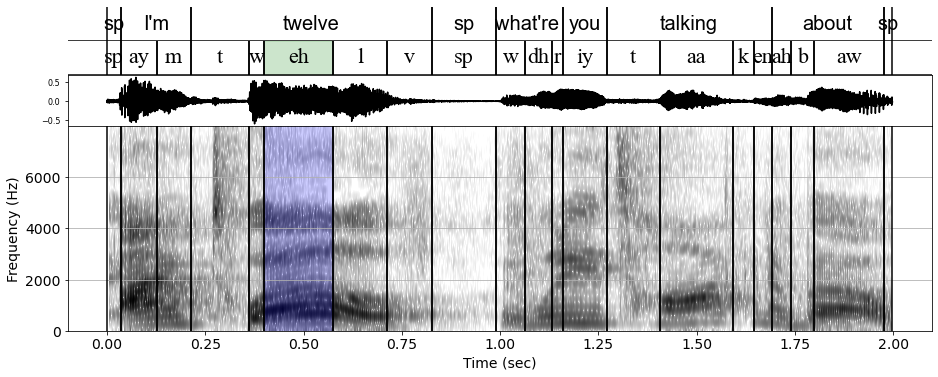

In [23]:
# create a figure with the panes that we want in it
height_ratios = [1, 1, 1.5, 6]  # relative heights of four panes
fig,[wrd,phn,wav,specgrm] = phon.make_figure(height_ratios)

start = 0
end = -1

# fill the figure with textgrid and acoustic data
phon.display_wave(x,fs,start, end, ylabel="", font_size=8, ax=wav)
phon.sgram(x,fs,start, end, ax=specgrm)

phon.plot_tier(phdf, start, end, ax=phn, 
               fontname = "Doulos SIL", fontsize = 22,
               mark_in_plot=[specgrm],
               span_time=0.5)
phon.plot_tier(wddf, start, end, ax=wrd, 
               fontname = "Arial", fontsize = 20)

## d. Select measurement points

We will take a subset of the dataframe - so we are just looking at vowels, then we will specify some timepoints in each vowel for which we plan to take measurements.

* df.query() to get a subset of observations based on a test
* phon.explode_intervals() to choose observation points between intervals on a tier

In [24]:
vowels = ['ay', 'eh', 'iy', 'aa', 'aw']
vdf = tgdf.query(f'phone in {vowels}').copy()  # make a dataframe that just has vowels
vdf = phon.explode_intervals([0.2,0.5, 0.8], ts=['t1', 't2'], df=vdf) # get times for observations
vdf['vowel_dur'] = (vdf['t2'] - vdf['t1'])*1000  # add a vowel duration column

vdf.head()

,t1,t2,prev_phone1,phone,next_phone1,word,obs_t,obs_id,vowel_dur
1,0.035047,0.126541,sp,ay,m,I'm,0.053346,0.2,91.494109
1,0.035047,0.126541,sp,ay,m,I'm,0.080794,0.5,91.494109
1,0.035047,0.126541,sp,ay,m,I'm,0.108243,0.8,91.494109
5,0.398940,0.574179,w,eh,l,twelve,0.433988,0.2,175.238422
5,0.398940,0.574179,w,eh,l,twelve,0.48656,0.5,175.238422


### Exercise

* Convert the vowel duration measurements to milliseconds.
* Create a "consonants" dataframe
* How would you add a column to record a segmental feature, like 'diphthong'?


In [25]:
### ------ HINT  ----------
# see the file phoneclass.csv for a feature definition, we can use pandas merge() to 
#   add that info to the textgrid dataframe

phclass = pd.read_csv('phoneclass.csv')
with_features = tgdf.merge(phclass, on='phone', how='left').fillna('None')

with_features.head()

,t1,t2,prev_phone1,phone,next_phone1,word,majclass
0,0.000000,0.035047,,sp,ay,sp,None
1,0.035047,0.126541,sp,ay,m,I'm,vowel
2,0.126541,0.213045,ay,m,t,I'm,nasal
3,0.213045,0.361099,m,t,w,twelve,stop
4,0.361099,0.398940,t,w,eh,twelve,glide


## e. Merge formant measurements with TextGrid info

* we saw already how we can save a dataframe to a csv file with df.to_csv()
* we will also use pd.read_csv() to read the csv back into a dataframe
* So here we use the formants calculated and saved earlier
* Merge the formant dataframe with the textgrid dataframe
  

In [26]:
fmtsdf = pd.read_csv('im_twelve.csv')  # read in the csv of formants measurements

vdf = phon.interpolate_measures(
    meas_df=fmtsdf[['sec','F1', 'F2', 'F3', 'F4']],  # meas_ts and cols to interpolate only
    meas_ts='sec',        # time index in the measurements dataframe
    interp_df=vdf,       # textgrid dataframe
    interp_ts='obs_t',  # target observation times in the textgrid
    overwrite=True
)
vdf.head()

,t1,t2,prev_phone1,phone,next_phone1,word,obs_t,obs_id,vowel_dur,F1,F2,F3,F4
1,0.035047,0.126541,sp,ay,m,I'm,0.053346,0.2,91.494109,1062.461865,1544.881392,2944.392614,3987.599500
1,0.035047,0.126541,sp,ay,m,I'm,0.080794,0.5,91.494109,844.930370,1637.327317,2920.901107,4031.768843
1,0.035047,0.126541,sp,ay,m,I'm,0.108243,0.8,91.494109,1042.465995,1820.000675,2983.483217,4032.916539
5,0.398940,0.574179,w,eh,l,twelve,0.433988,0.2,175.238422,837.505868,1613.277555,2835.112457,4270.416410
5,0.398940,0.574179,w,eh,l,twelve,0.48656,0.5,175.238422,698.414761,1477.701072,2971.428673,4248.436506


## f. Visualize formants at vowel measurement points

<Axes: xlabel='Time (sec)', ylabel='Frequency (Hz)'>

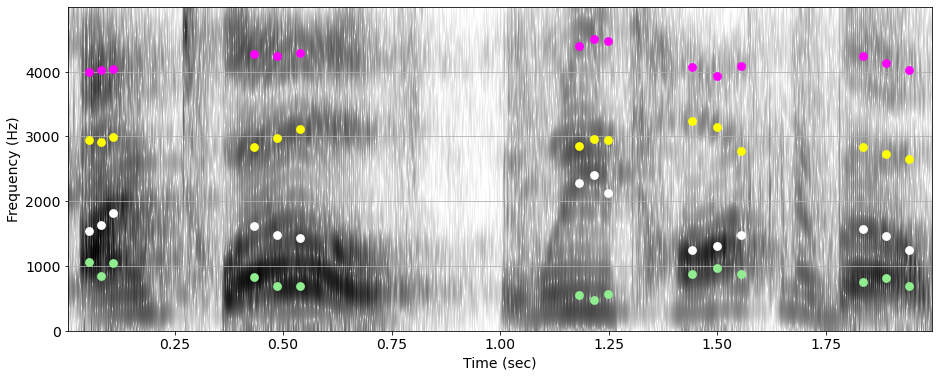

In [27]:
phon.sgram(x,fs,tf=5000)

sns.pointplot(vdf,x='obs_t',y='F1',linestyle='none',native_scale=True,marker="o",color='lightgreen')
sns.pointplot(vdf,x='obs_t',y='F2',linestyle='none',native_scale=True,marker="o",color='white')
sns.pointplot(vdf,x='obs_t',y='F3',linestyle='none',native_scale=True,marker="o",color='yellow')
sns.pointplot(vdf,x='obs_t',y='F4',linestyle='none',native_scale=True,marker="o",color='magenta')

